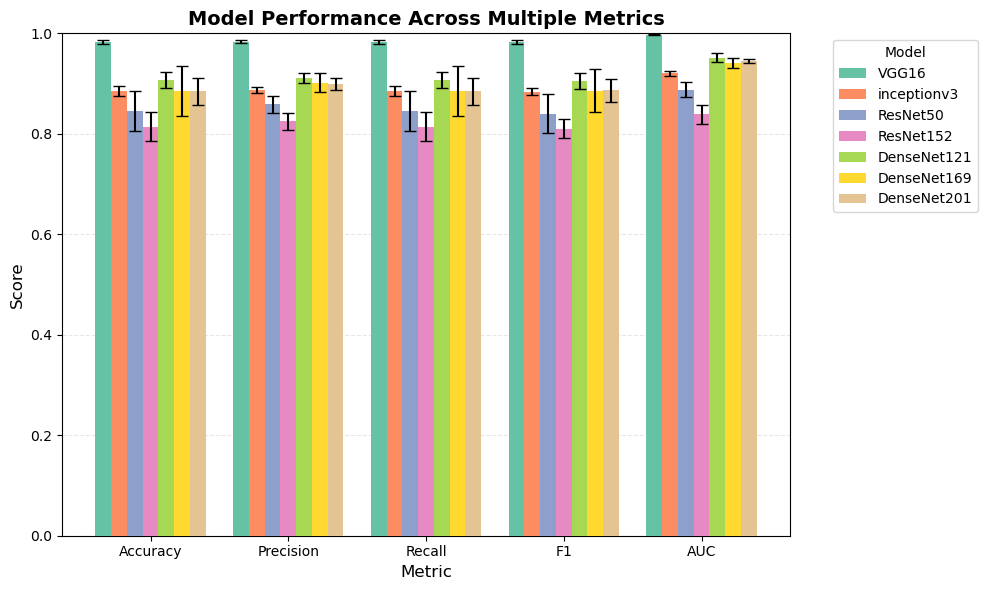

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 示例数据
data = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "AUC"],
    "VGG16_mean": [0.9833, 0.9836, 0.9833, 0.9833, 0.9975],
    "VGG16_std":  [0.0043, 0.0038, 0.0043, 0.0042, 0.0004],
    "ResNet50_mean": [0.8459, 0.8592, 0.8459, 0.8400, 0.8877],
    "ResNet50_std":  [0.0399, 0.0168, 0.0399, 0.0391, 0.0153],
    "ResNet152_mean": [0.8141, 0.8247, 0.8141, 0.8103, 0.8385],
    "ResNet152_std":  [0.0284, 0.0166, 0.0284, 0.0188, 0.0198],
    "inceptionv3_mean": [0.8847, 0.8871, 0.8847, 0.8837, 0.9202],
    "inceptionv3_std":  [0.0103, 0.0060, 0.0103, 0.0071, 0.0048],
    "DenseNet121_mean": [0.9070, 0.9118, 0.9070, 0.9057, 0.9510],
    "DenseNet121_std":  [0.0166, 0.0100, 0.0166, 0.0156, 0.0090],
    "DenseNet169_mean": [0.8856, 0.9015, 0.8856, 0.8858, 0.9409],
    "DenseNet169_std":  [0.0498, 0.0188, 0.0498, 0.0432, 0.0091],
    "DenseNet201_mean": [0.8848, 0.8990, 0.8848, 0.8863, 0.9446],
    "DenseNet201_std":  [0.0266, 0.0120, 0.0266, 0.0228, 0.0045]
}
df = pd.DataFrame(data)

# 固定顺序
metric_order = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
model_order  = ["VGG16", "inceptionv3", "ResNet50", "ResNet152", "DenseNet121", "DenseNet169", "DenseNet201"]

# 取指定顺序的数据表
df = df.set_index("Metric").loc[metric_order]

# 分组条形图手工定位
x = np.arange(len(metric_order))            # 每个指标的x位置
group_width = 0.8                           # 一组柱子的总宽度
bar_width   = group_width / len(model_order)

palette = sns.color_palette("Set2", n_colors=len(model_order))
fig, ax = plt.subplots(figsize=(10, 6))

for j, model in enumerate(model_order):
    means = df[f"{model}_mean"].values
    stds  = df[f"{model}_std"].values
    # 每个模型在一组里的位置：左移半组宽，再按列序加偏移
    pos = x - group_width/2 + bar_width/2 + j*bar_width

    # 误差线裁剪到 [0, 1]，避免越界
    upper = np.minimum(1.0, means + stds) - means
    lower = means - np.maximum(0.0, means - stds)
    yerr  = np.vstack([lower, upper])  # 非对称误差

    ax.bar(pos, means,
           width=bar_width,
           label=model,
           color=palette[j],
           edgecolor="none",
           linewidth=0.6,
           yerr=yerr,
           capsize=4,
           zorder=3)

# 坐标与样式
ax.set_xticks(x)
ax.set_xticklabels(metric_order)
ax.set_ylim(0, 1)  # 纵坐标 0~1
ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Metric", fontsize=12)
ax.set_title("Model Performance Across Multiple Metrics", fontsize=14, weight="bold")
ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

In [3]:
import pandas as pd

# 读取 Excel 文件
df_2023 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2023-冷冻.xls")
df_2024 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2024-冷冻.xls")
df_2025 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2025-冷冻.xls")

df_all = pd.concat([df_2023, df_2024, df_2025], ignore_index=True)

keep_cols = [
    "女病人ID",
    "ARTID",
    "年龄",
    "Bmi(新鲜周期)",
    "移植胚胎存活细胞数1",
    "移植胚胎存活细胞数2",
    "移植数",
    "妊娠结局",
    "胎儿数"
]

df_selected = df_all[[col for col in keep_cols if col in df_all.columns]]

# === 步骤 1: 仅保留 移植胚胎存活细胞数1 > 20 的行 ===
df_selected.loc[:, "移植胚胎存活细胞数1"] = (
    pd.to_numeric(df_selected["移植胚胎存活细胞数1"], errors="coerce")
    .astype("Int64")
)
df_selected = df_selected[pd.to_numeric(df_selected["移植胚胎存活细胞数1"], errors="coerce") > 20]

# === 步骤 2: 将 移植胚胎存活细胞数1 转为字符型 ===
df_selected["移植胚胎存活细胞数1"] = df_selected["移植胚胎存活细胞数1"].astype(str)

# === 步骤 3: 保留 胎儿数 == 0 或 胎儿数 == 移植数 的行 ===
df_selected["胎儿数"] = pd.to_numeric(df_selected["胎儿数"], errors="coerce")
df_selected["移植数"] = pd.to_numeric(df_selected["移植数"], errors="coerce")

df_filtered = df_selected[
    (df_selected["胎儿数"] == 0) |
    (df_selected["胎儿数"] == df_selected["移植数"])
].copy()

df_filtered = df_filtered.dropna(subset=["妊娠结局"]).copy()
# === 输出结果 ===
print(df_filtered.shape)
print(df_filtered.head)

(2747, 9)
<bound method NDFrame.head of        女病人ID   ARTID    年龄  Bmi(新鲜周期) 移植胚胎存活细胞数1  移植胚胎存活细胞数2  移植数  妊娠结局  胎儿数
3     269895  216874  31.3      18.96        411         NaN    1  临床妊娠    1
4     264407  217041  24.1      21.22        423         NaN    1  临床妊娠    0
5     271697  217922  42.6      25.33        411         NaN    1  临床妊娠    0
6     266918  218241  30.4      19.05        412         NaN    1  临床妊娠    1
7     271114  218791  38.6      23.83        422         NaN    1  临床妊娠    1
...      ...     ...   ...        ...        ...         ...  ...   ...  ...
3688  234340  369002  35.3      19.53        412         NaN    1   未妊娠    0
3691  305431  369547  30.6      18.29        422         NaN    1  生化妊娠    0
3699  289487  370440  36.5      24.09        411         NaN    1  生化妊娠    0
3703  296780  371221  39.8      23.44        323         NaN    1   未妊娠    0
3706  318372  371961  28.9      18.37        411         NaN    1   未妊娠    0

[2747 rows x 9 columns]>


/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_69858/3343669147.py:25: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '<IntegerArray>
[  8,   7,   7, 411, 423, 411, 412, 422, 412, 412,
 ...
 412, 323, 411, 411,   7, 323, 312, 323, 423, 411]
Length: 3723, dtype: Int64' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df_selected.loc[:, "移植胚胎存活细胞数1"] = (


In [4]:
import pandas as pd

# 确保类型正确
df_filtered["移植胚胎存活细胞数1"] = df_filtered["移植胚胎存活细胞数1"].astype(str)
df_filtered["妊娠结局"] = df_filtered["妊娠结局"].astype(str)
df_filtered = df_filtered[df_filtered["移植胚胎存活细胞数1"].str.len() >= 3].copy()

# 统计每种胚胎质量的妊娠情况
preg_stats = (
    df_filtered
    .groupby("移植胚胎存活细胞数1")
    .agg(
        总数=("妊娠结局", "count"),
        临床妊娠数=("妊娠结局", lambda x: (x == "临床妊娠").sum())
    )
    .reset_index()
)

# 计算妊娠率（百分比）
preg_stats["妊娠概率"] = preg_stats["临床妊娠数"] / preg_stats["总数"] * 100

# 排序（从高到低）
preg_stats = preg_stats.sort_values("妊娠概率", ascending=False)

# 定义转换函数
def convert_to_grade(code):
    code = str(code)
    if len(code) != 3:
        return None
    mapping = {"1": "A", "2": "B", "3": "C"}
    first = code[0]
    second = mapping.get(code[1], "?")
    third = mapping.get(code[2], "?")
    return f"{first}{second}{third}"

# 在 preg_stats 上添加囊胚等级列
preg_stats["囊胚等级"] = preg_stats["移植胚胎存活细胞数1"].apply(convert_to_grade)
preg_stats["Expansion"] = preg_stats["囊胚等级"].str[0]
preg_stats["ICM"] = preg_stats["囊胚等级"].str[1]
preg_stats["TE"] = preg_stats["囊胚等级"].str[2]

# 重新排列列顺序
preg_stats = preg_stats[
    ["囊胚等级", "Expansion", "ICM", "TE", "总数", "临床妊娠数", "妊娠概率"]
]

# 输出结果
print("各胚胎质量对应妊娠概率：")
print(preg_stats)

各胚胎质量对应妊娠概率：
   囊胚等级 Expansion ICM TE   总数  临床妊娠数        妊娠概率
17  5BA         5   B  A    1      1  100.000000
15  5AA         5   A  A   12     12  100.000000
18  5BB         5   B  B    5      4   80.000000
4   3BA         3   B  A    4      3   75.000000
7   4AA         4   A  A  990    713   72.020202
10  4BA         4   B  A  105     74   70.476190
21  6AA         6   A  A   13      9   69.230769
24  6BA         6   B  A    3      2   66.666667
8   4AB         4   A  B  425    279   65.647059
1   3AA         3   A  A   17     11   64.705882
2   3AB         3   A  B   55     31   56.363636
9   4AC         4   A  C   32     18   56.250000
11  4BB         4   B  B  315    177   56.190476
16  5AB         5   A  B    4      2   50.000000
19  5BC         5   B  C    4      2   50.000000
5   3BB         3   B  B  140     62   44.285714
12  4BC         4   B  C  398    172   43.216080
25  6BB         6   B  B    7      3   42.857143
6   3BC         3   B  C  191     72   37.696335
26  6BC

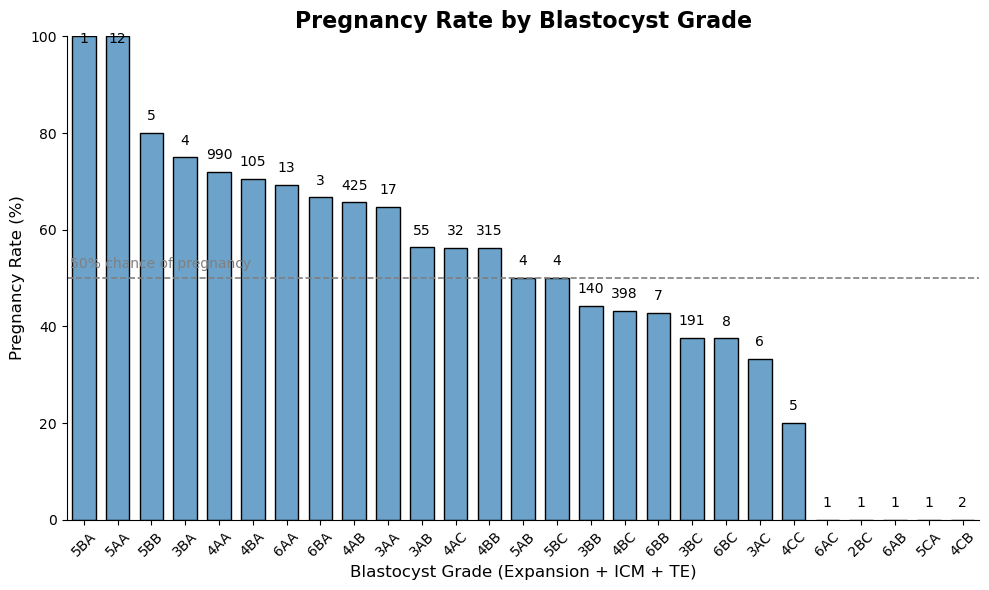

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 6))

bar_color = "#5DA5DA"  # 清爽蓝，可换成别的十六进制颜色

sns.barplot(
    data=preg_stats,
    x="囊胚等级",
    y="妊娠概率",
    color=bar_color,
    edgecolor="black",
    width=0.7,
    ax=ax
)

# --- Titles and labels (English) ---
ax.set_title("Pregnancy Rate by Blastocyst Grade", fontsize=16, fontweight="bold")
ax.set_xlabel("Blastocyst Grade (Expansion + ICM + TE)", fontsize=12)
ax.set_ylabel("Pregnancy Rate (%)", fontsize=12)

# --- Add a 50% reference line ---
ax.set_ylim(0, 100)
ax.axhline(50, linestyle="--", linewidth=1.2, color="gray")
ax.text(
    x=-0.4, y=52, s="50% chance of pregnancy", color="gray",
    fontsize=10
)

categories = [t.get_text() for t in ax.get_xticklabels()]
counts = (
    preg_stats.set_index("囊胚等级")
              .reindex(categories)["总数"]
              .fillna(0).astype(int)
    .tolist()
)

for patch, n in zip(ax.patches, counts):
    x = patch.get_x() + patch.get_width() / 2.0   # 柱子中心
    y = patch.get_height()                        # 柱子高度（=妊娠率）
    y_label = min(y + 2, 98)                      # 往上抬一点，且不超出顶部
    ax.text(x, y_label, n, ha="center", va="bottom",
            fontsize=10, color="black")
# --- Style ---
ax.tick_params(axis="x", rotation=45)
sns.despine()
plt.tight_layout()
plt.show()

/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_69858/149877382.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


✅ 各质量类别妊娠成功率：
        Quality  Total  Pregnant  Pregnancy Rate (%)
1  Good-quality   1630      1137           69.754601
0  Fair-quality    493       261           52.941176
2  Poor-quality    623       255           40.930979


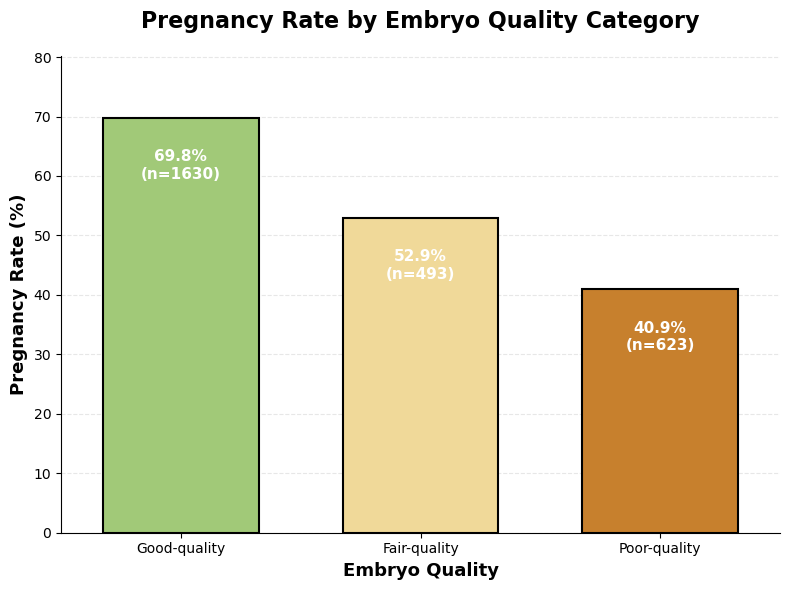

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 假设已有 preg_stats，包含列 ["囊胚等级", "总数", "临床妊娠数", "妊娠概率"]

# -------------------------------
# 1️⃣ 分类函数
# -------------------------------
def classify_quality(grade):
    grade = str(grade)
    if len(grade) < 3:
        return "Unknown"
    expansion, icm, te = grade[0], grade[1], grade[2]

    # Fair-quality (exact matches)
    if grade in ["3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"]:
        return "Fair-quality"
    # Good-quality: extension ≥3 and (AA or AB or BA)
    elif expansion >= "3" and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    else:
        return "Poor-quality"

# -------------------------------
# 2️⃣ 添加分类列
# -------------------------------
preg_stats["Quality"] = preg_stats["囊胚等级"].apply(classify_quality)

# -------------------------------
# 3️⃣ 按 Quality 统计妊娠率
# -------------------------------
quality_stats = (
    preg_stats
    .groupby("Quality")
    .agg(
        Total=("总数", "sum"),
        Pregnant=("临床妊娠数", "sum")
    )
    .reset_index()
)
quality_stats["Pregnancy Rate (%)"] = quality_stats["Pregnant"] / quality_stats["Total"] * 100

# 🔥 定义质量顺序（从好到差）
quality_order = ["Good-quality", "Fair-quality", "Poor-quality"]
quality_stats["Quality"] = pd.Categorical(
    quality_stats["Quality"],
    categories=quality_order,
    ordered=True
)
quality_stats = quality_stats.sort_values("Quality")

print("✅ 各质量类别妊娠成功率：")
print(quality_stats)

# -------------------------------
# 4️⃣ 绘图
# -------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

# 🎨 配色：绿色(Good) → 黄色(Fair) → 橙色(Poor)
palette = ["#A1D76A", "#FEE08B", "#E08214"] 

sns.barplot(
    data=quality_stats,
    x="Quality",
    y="Pregnancy Rate (%)",
    palette=palette,
    edgecolor="black",
    linewidth=1.5,
    width=0.65,
    ax=ax,
    order=quality_order  # 🔥 强制顺序
)

# 🏷️ 添加数值标签（优化位置）
for i, row in quality_stats.iterrows():
    rate = row["Pregnancy Rate (%)"]
    total = int(row["Total"])

    # 📍 标签位置自适应：柱子高时放内部，低时放外部
    if rate > 15:
        y_pos = rate - 8  # 放在柱子内部
        color = "white"
        weight = "bold"
    else:
        y_pos = rate + 3  # 放在柱子上方
        color = "black"
        weight = "normal"

    ax.text(
        quality_order.index(row["Quality"]),  # x位置
        y_pos,
        f"{rate:.1f}%\n(n={total})",
        ha="center",
        va="center" if rate > 15 else "bottom",
        fontsize=11,
        color=color,
        weight=weight
    )

# -------------------------------
# 5️⃣ 美化
# -------------------------------
ax.set_title("Pregnancy Rate by Embryo Quality Category",
             fontsize=16, fontweight="bold", pad=20)
ax.set_xlabel("Embryo Quality", fontsize=13, fontweight="bold")
ax.set_ylabel("Pregnancy Rate (%)", fontsize=13, fontweight="bold")
ax.set_ylim(0, max(quality_stats["Pregnancy Rate (%)"]) * 1.15)  # 动态上限

# 🎯 网格线（仅横向）
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()


In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ===============================
# 1️⃣ 数据预处理
# ===============================
# 确保类型正确
df_filtered["移植胚胎存活细胞数1"] = df_filtered["移植胚胎存活细胞数1"].astype(str)
df_filtered["妊娠结局"] = df_filtered["妊娠结局"].astype(str)

# 仅保留长度≥3的编码（如 411、422 等）
df_filtered = df_filtered[df_filtered["移植胚胎存活细胞数1"].str.len() >= 3].copy()

# ===============================
# 2️⃣ 数字编码 → 囊胚等级（4AA 等）
# ===============================
def convert_to_grade(code):
    code = str(code)
    if len(code) != 3:
        return None
    mapping = {"1": "A", "2": "B", "3": "C"}
    first = code[0]         # 扩张度
    second = mapping.get(code[1], "?")  # ICM
    third = mapping.get(code[2], "?")   # TE
    return f"{first}{second}{third}"

df_filtered["囊胚等级"] = df_filtered["移植胚胎存活细胞数1"].apply(convert_to_grade)

# ===============================
# 3️⃣ 囊胚等级 → 质量分类
# ===============================
def classify_quality(grade):
    grade = str(grade)
    if len(grade) < 3:
        return "Unknown"
    expansion, icm, te = grade[0], grade[1], grade[2]

    # Fair-quality（中等质量）
    if grade in ["3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"]:
        return "Fair-quality"
    # Good-quality：扩张度 ≥3 且 (AA / AB / BA)
    elif expansion >= "3" and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    else:
        return "Poor-quality"

df_filtered["Quality"] = df_filtered["囊胚等级"].apply(classify_quality)

# ===============================
# 4️⃣ 保存完整表格（每条记录带 Quality）
# ===============================
df_filtered.to_csv("Embryo_FullStats_withQuality.csv", index=False, encoding="utf-8-sig")

✅ 各年龄段统计：
     年龄段    人数        百分比
0  18-24    91   2.091473
1  25-29   937  21.535279
2  30-34  1742  40.036773
3  35-39  1063  24.431165
4  40-44   455  10.457366
5    ≥45    63   1.447943


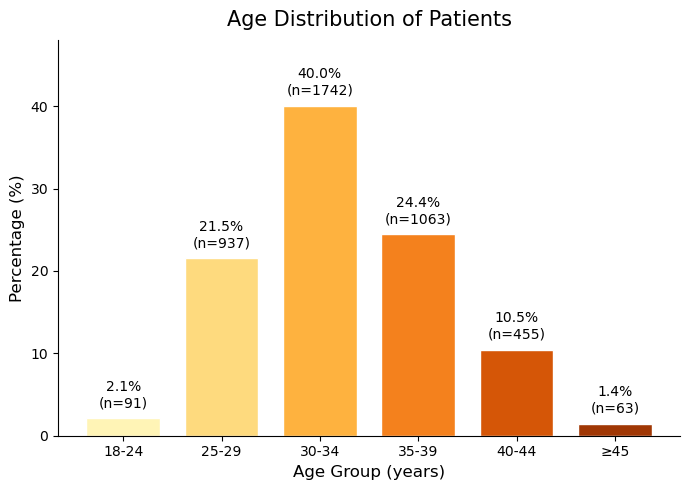

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ==============================
# 1️⃣ 读取与清洗数据
# ==============================
df_age = pd.read_csv("/Users/lzz/Documents/GitHub/IVF_AI/SlidePatientBirthDates.csv")

df_age["Age"] = pd.to_numeric(df_age["Age"], errors="coerce")
df_age = df_age[df_age["Age"].notna() & (df_age["Age"] >= 18) & (df_age["Age"] <= 100)].copy()

# ==============================
# 2️⃣ 按年龄区间分组
# ==============================
bins = [18, 25, 30, 35, 40, 45, 100]
labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "≥45"]
df_age["年龄段"] = pd.cut(df_age["Age"], bins=bins, labels=labels, right=False)

# ==============================
# 3️⃣ 统计每个年龄段的数量与百分比
# ==============================
age_stats = (
    df_age["年龄段"]
    .value_counts()
    .sort_index()
    .reset_index()
)
age_stats.columns = ["年龄段", "人数"]
age_stats["百分比"] = age_stats["人数"] / age_stats["人数"].sum() * 100

print("✅ 各年龄段统计：")
print(age_stats)

# ==============================
# 4️⃣ 设置配色
# ==============================
colors = sns.color_palette("YlOrBr", n_colors=len(age_stats))

# ==============================
# 5️⃣ 绘图
# ==============================
plt.figure(figsize=(7, 5))
bars = plt.bar(
    age_stats["年龄段"],
    age_stats["百分比"],
    color=colors,
    edgecolor="white",
    width=0.75
)

# ==============================
# 6️⃣ 美化图形
# ==============================
plt.title("Age Distribution of Patients", fontsize=15, pad=10)
plt.xlabel("Age Group (years)", fontsize=12)
plt.ylabel("Percentage (%)", fontsize=12)
plt.ylim(0, age_stats["百分比"].max() * 1.2)

# 添加百分比与人数标签
for i, row in age_stats.iterrows():
    plt.text(
        i, row["百分比"] + 1,
        f"{row['百分比']:.1f}%\n(n={row['人数']})",
        ha='center', va='bottom', fontsize=10
    )

sns.despine()
plt.tight_layout()
plt.show()

✅ 各年龄段妊娠率：

/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_69858/3958504813.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("年龄段")



     年龄段    总数  临床妊娠数     妊娠率(%)
0  18-24    73     51  69.863014
1  25-29   686    479  69.825073
2  30-34  1131    730  64.544651
3  35-39   625    333  53.280000
4  40-44   223     59  26.457399
5   >=45     8      1  12.500000


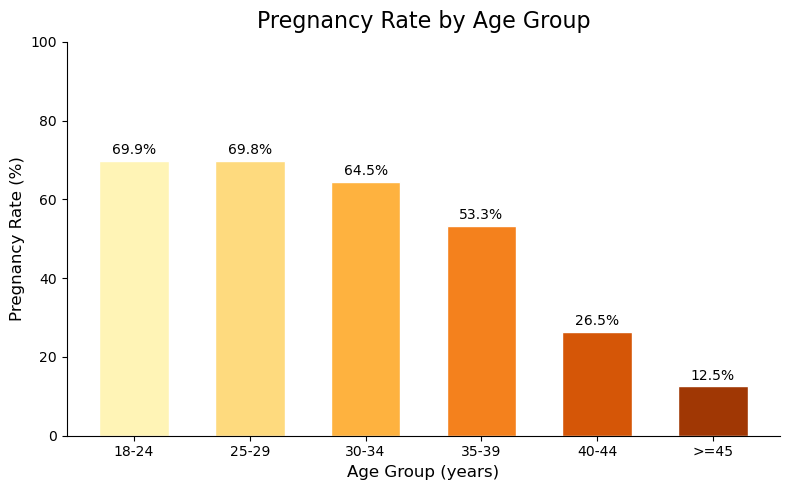

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ==============================
# 1️⃣ 数据准备
# ==============================
df_filtered["年龄"] = pd.to_numeric(df_filtered["年龄"], errors="coerce")

# 年龄区间
bins = [18, 25, 30, 35, 40, 45, 100]
labels = ["18-24", "25-29", "30-34", "35-39", "40-44", ">=45"]
df_filtered["年龄段"] = pd.cut(df_filtered["年龄"], bins=bins, labels=labels, right=False)

# 各年龄段妊娠率
age_stats = (
    df_filtered
    .groupby("年龄段")
    .agg(
        总数=("妊娠结局", "count"),
        临床妊娠数=("妊娠结局", lambda x: (x == "临床妊娠").sum())
    )
    .reset_index()
)
age_stats["妊娠率(%)"] = age_stats["临床妊娠数"] / age_stats["总数"] * 100

print("✅ 各年龄段妊娠率：")
print(age_stats)

# ==============================
# 2️⃣ 自定义渐变配色（黄色→橙色）
# ==============================
colors = sns.color_palette("YlOrBr", n_colors=len(age_stats))  # 黄色到橙棕色渐变
# 或者更亮：sns.color_palette("YlOrRd", n_colors=len(age_stats))

# ==============================
# 3️⃣ 绘图
# ==============================
plt.figure(figsize=(8, 5))

bars = plt.bar(
    age_stats["年龄段"],
    age_stats["妊娠率(%)"],
    color=colors,
    edgecolor="white",
    width=0.6
)

# ==============================
# 4️⃣ 美化
# ==============================
plt.title("Pregnancy Rate by Age Group", fontsize=16, pad=10)
plt.xlabel("Age Group (years)", fontsize=12)
plt.ylabel("Pregnancy Rate (%)", fontsize=12)
plt.ylim(0, 100)

# 添加柱顶数值
for i, row in age_stats.iterrows():
    plt.text(i, row["妊娠率(%)"] + 1, f"{row['妊娠率(%)']:.1f}%", 
             ha='center', va='bottom', fontsize=10)

# 优化外观
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import re
from CHAID import Tree

# ==============================
# 1️⃣ 数据加载与清洗
# ==============================
df = df_filtered.copy()

df["年龄"] = pd.to_numeric(df["年龄"], errors="coerce")
df["Bmi(新鲜周期)"] = pd.to_numeric(df["Bmi(新鲜周期)"], errors="coerce")

# 保留有效妊娠结局
df["Pregnancy"] = (df["妊娠结局"] == "临床妊娠").astype(int)

print(df.shape)

# ==============================
# 2️⃣ 胚胎编码规范化
# ==============================
def to_abc_grade(x):
    if pd.isna(x): return None
    s = str(x).strip().upper()
    s = re.sub(r'[^0-9A-Z]', '', s)
    if len(s) < 3 or not s[0].isdigit():
        return None
    exp = s[0]
    tail = s[1:]
    if len(tail) < 2:
        return None
    c2, c3 = tail[0], tail[1]
    d2l = {'1': 'A', '2': 'B', '3': 'C'}
    def norm_one(ch):
        if ch in d2l: return d2l[ch]
        if ch in ('A','B','C'): return ch
        return None
    icm, te = norm_one(c2), norm_one(c3)
    if icm is None or te is None:
        return None
    return f"{exp}{icm}{te}"

df["GradeABC"] = df["移植胚胎存活细胞数1"].apply(to_abc_grade)
df = df[df["GradeABC"].notna()].copy()

# ==============================
# 3️⃣ 按规则划分胚胎质量
# ==============================
FAIR_SET = {"3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"}

def classify_quality(grade_abc):
    exp, icm, te = grade_abc[0], grade_abc[1], grade_abc[2]
    if grade_abc in FAIR_SET:
        return "Fair-quality"
    if int(exp) >= 3 and (
        (icm == "A" and te == "A") or
        (icm == "A" and te == "B") or
        (icm == "B" and te == "A")
    ):
        return "Good-quality"
    return "Poor-quality"

df["Quality"] = df["GradeABC"].apply(classify_quality)
df = df[df["Quality"].isin(["Good-quality", "Poor-quality"])].copy()
df["Quality"] = df["Quality"].astype("category")

# ==============================
# 4️⃣ 年龄分组
# ==============================
bins = [-np.inf, 30, 32, 34, 36, 38, 40, np.inf]
labels = ["≤30", "31–32", "33–34", "35–36", "37–38", "39–40", "≥41"]
df["AgeGroup"] = pd.cut(df["年龄"], bins=bins, labels=labels, right=True)
df = df[df["AgeGroup"].notna()].copy()
df["AgeGroup"] = df["AgeGroup"].astype("category")

# ==============================
# 5️⃣ BMI 分组（根据 WHO 标准）
# ==============================
def bmi_group(bmi):
    if pd.isna(bmi):
        return None
    if bmi < 18.5:
        return "Underweight"
    elif bmi < 24:
        return "Normal"
    elif bmi < 28:
        return "Overweight"
    else:
        return "Obese"

df["BMIgroup"] = df["Bmi(新鲜周期)"].apply(bmi_group)
df = df[df["BMIgroup"].notna()].copy()
df["BMIgroup"] = df["BMIgroup"].astype("category")

print("\n✅ 胚胎质量分布：")
print(df["Quality"].value_counts())
print("\n✅ 年龄组分布：")
print(df["AgeGroup"].value_counts())
print("\n✅ BMI 分布：")
print(df["BMIgroup"].value_counts())

# ==============================
# 6️⃣ 构建 CHAID 决策树
# ==============================
variables = {
    'AgeGroup': 'nominal',
    'Quality': 'nominal',
    'BMIgroup': 'nominal'
}

chaid_tree = Tree.from_pandas_df(
    df,
    variables,
    'Pregnancy',
    max_depth=5,
    min_child_node_size=20
)

# ==============================
# 7️⃣ 输出结果
# ==============================
print("\n📊 CHAID 决策树结构：")
chaid_tree.print_tree()


(2746, 13)

✅ 胚胎质量分布：
Quality
Good-quality    1613
Poor-quality     592
Name: count, dtype: int64

✅ 年龄组分布：
AgeGroup
≤30      657
31–32    407
33–34    341
35–36    340
37–38    190
≥41      146
39–40    124
Name: count, dtype: int64

✅ BMI 分布：
BMIgroup
Normal         1338
Overweight      479
Underweight     230
Obese           158
Name: count, dtype: int64

📊 CHAID 决策树结构：
([], {0: 830.0, 1: 1375.0}, (Quality, p=9.522604677091904e-33, score=142.04173493851562, groups=[['Good-quality'], ['Poor-quality']]), dof=1))
|-- (['Good-quality'], {0: 487.0, 1: 1126.0}, (AgeGroup, p=1.4978042471349754e-16, score=72.8747225749869, groups=[['31–32', '≤30', '33–34'], ['35–36', '37–38', '39–40'], ['≥41']]), dof=2))
|   |-- (['31–32', '≤30', '33–34'], {0: 265.0, 1: 812.0}, <Invalid Chaid Split> - p-value greater than alpha merge)
|   |-- (['35–36', '37–38', '39–40'], {0: 171.0, 1: 287.0}, <Invalid Chaid Split> - p-value greater than alpha merge)
|   +-- (['≥41'], {0: 51.0, 1: 27.0}, <Invalid Chaid Spli

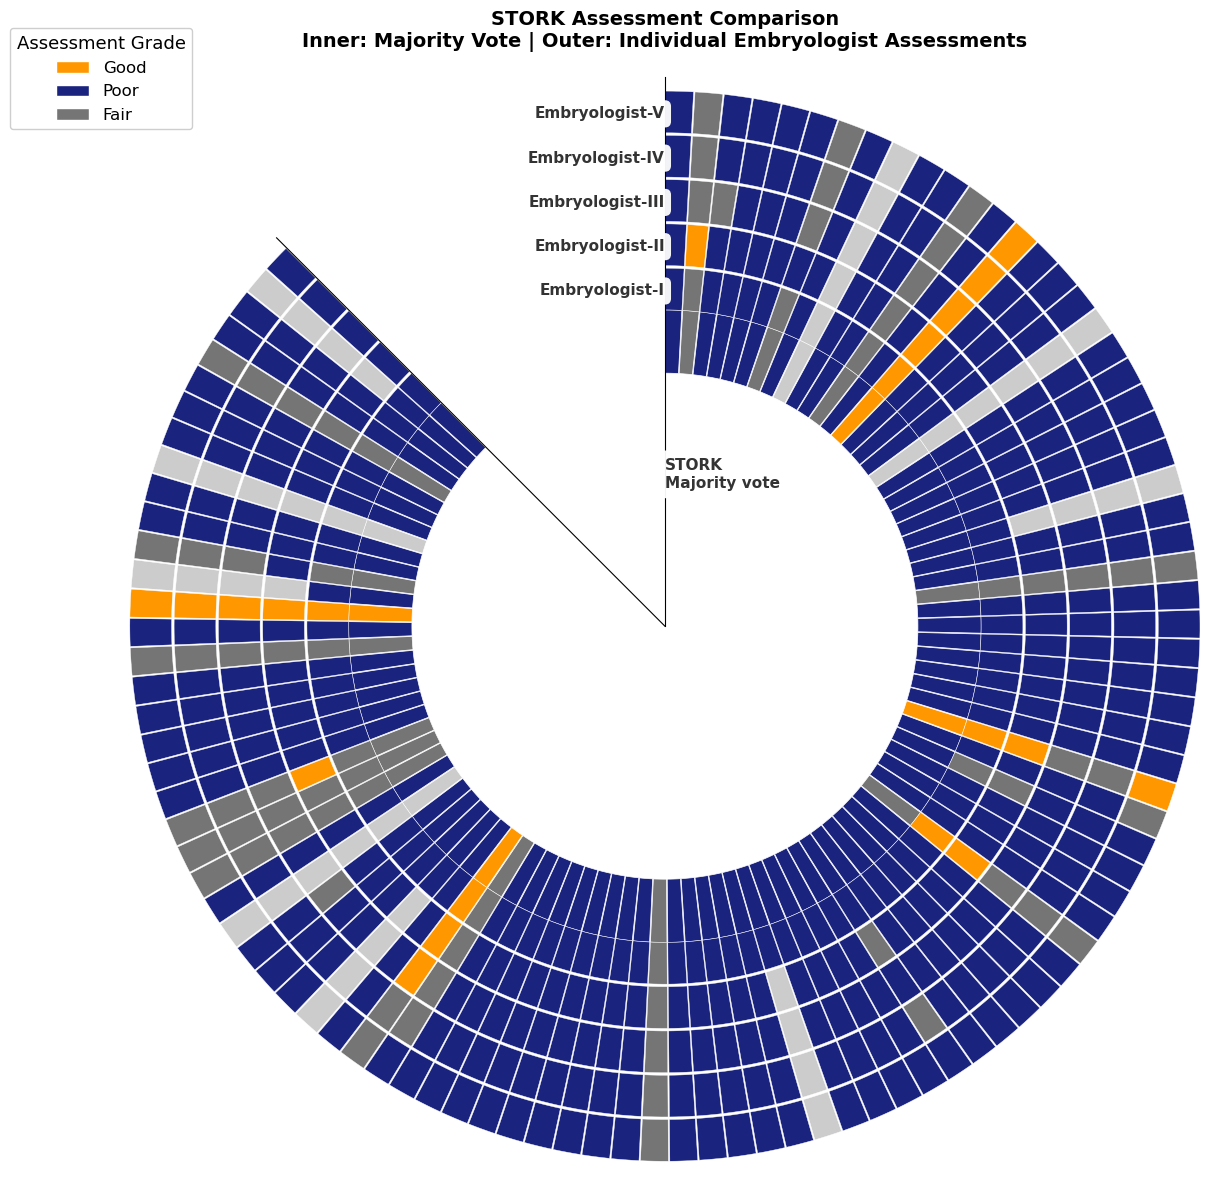

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# =========================
# 1️⃣ 读取和处理数据
# =========================
df = pd.read_csv("../../Assessment_comparison.csv", sep="\t|,|;", engine="python")
df.rename(columns={df.columns[0]: "EmbryoID"}, inplace=True)

def map_quality(grade):
    """按照标准分类质量"""
    if not isinstance(grade, str):
        return np.nan
    grade = grade.strip().upper()
    if "MORULA" in grade:
        return "Morula"
    if len(grade) < 3:
        return np.nan
    expansion, icm, te = grade[0], grade[1], grade[2]
    grade_3char = grade[:3]
    if grade_3char in ["3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"]:
        return "Fair"
    elif expansion >= "3" and (
        (icm == "A" and te == "A")
        or (icm == "A" and te == "B")
        or (icm == "B" and te == "A")
    ):
        return "Good"
    else:
        return "Poor"

cols = df.columns[1:]
for col in cols:
    df[col + "_quality"] = df[col].apply(map_quality)

def majority_vote(row):
    votes = row[[c + "_quality" for c in cols]].dropna().values
    if len(votes) == 0:
        return np.nan
    vals, counts = np.unique(votes, return_counts=True)
    return vals[np.argmax(counts)]

df["MajorityVote"] = df.apply(majority_vote, axis=1)

# =========================
# 2️⃣ 颜色与映射
# =========================
color_map = {"Good": "#FF9800", "Poor": "#1A237E", "Fair": "#757575"}
expert_map = {
    "A": "Embryologist-I",
    "B": "Embryologist-II",
    "C": "Embryologist-III",
    "D": "Embryologist-IV",
    "F": "Embryologist-V",
}

# =========================
# 3️⃣ 创建圆环图（留白左上 1/8）
# =========================
fig, ax = plt.subplots(figsize=(14, 12), subplot_kw=dict(projection="polar"))

n_embryos = len(df)
angle_start = np.deg2rad(225)     # 起始角度（左下）
angle_range = np.deg2rad(315)     # 显示 7/8 圆（留白左上 1/8）
angle_per_embryo = angle_range / n_embryos

# 绘制每个胚胎的环形条
for embryo_idx, (_, row) in enumerate(df.iterrows()):
    start_angle = angle_start + embryo_idx * angle_per_embryo
    angle = start_angle + angle_per_embryo / 2
    width = angle_per_embryo * 0.95

    # 内层：多数投票
    consensus_color = color_map.get(row["MajorityVote"], "#CCCCCC")
    ax.bar(
        angle, 0.5, width=width, bottom=2.0,
        color=consensus_color, edgecolor="white", linewidth=0.5
    )

    # 外层：五位专家
    expert_order = ["A", "B", "C", "D", "F"]
    for i, code in enumerate(expert_order):
        quality_color = color_map.get(row[code + "_quality"], "#CCCCCC")
        r_inner = 2.5 + i * 0.35
        ax.bar(
            angle, 0.33, width=width, bottom=r_inner,
            color=quality_color, edgecolor="white", linewidth=0.3
        )

# =========================
# 4️⃣ 标签
# =========================
label_radii = [2.65, 3.00, 3.35, 3.70, 4.05]
label_angle = np.deg2rad(225)
for code, radius in zip(["A", "B", "C", "D", "F"], label_radii):
    ax.text(
        label_angle, radius, expert_map[code],
        ha="right", va="center", fontsize=11, fontweight="bold",
        color="#333333",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.95, edgecolor="none"),
    )

ax.text(
    label_angle, 1.2, "STORK\nMajority vote",
    ha="left", va="center", fontsize=11, fontweight="bold",
    color="#333333",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.95, edgecolor="none"),
)

# =========================
# 5️⃣ 样式设置（关键：顺时针旋转 90°）
# =========================
ax.set_theta_offset(np.deg2rad(-45))  # ⬅ 顺时针旋转 90°
ax.set_theta_direction(-1)            # 顺时针方向
ax.set_thetamin(225)
ax.set_thetamax(540)

ax.set_xticks([])
ax.set_yticks([])
ax.spines["polar"].set_visible(False)
ax.grid(False)

# 图例
legend_elems = [
    mpatches.Patch(facecolor=color_map["Good"], edgecolor="white", label="Good"),
    mpatches.Patch(facecolor=color_map["Poor"], edgecolor="white", label="Poor"),
    mpatches.Patch(facecolor=color_map["Fair"], edgecolor="white", label="Fair"),
]
ax.legend(
    handles=legend_elems,
    loc="upper left",
    bbox_to_anchor=(-0.1, 1.05),
    fontsize=12,
    title="Assessment Grade",
    title_fontsize=13,
    framealpha=0.95,
)

plt.title(
    "STORK Assessment Comparison\nInner: Majority Vote | Outer: Individual Embryologist Assessments",
    fontsize=14, fontweight="bold", pad=20,
)
plt.tight_layout()
plt.show()

/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 35745 (\N{CJK UNIFIED IDEOGRAPH-8BA1}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 22312 (\N{CJK UNIFIED IDEOGRAPH-5728}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 36825 (\N{CJK UNIFIED IDEOGRAPH-8FD9}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 20123 (\N{CJK UNIFIED IDEOGRAPH-4E9B}) missing from current font.
  fig.canvas.draw()
/Users/lzz/anaconda3/lib/python3.11/site-packages/seaborn/utils.py:61: UserWarning: Glyph 19987 (\N{CJK UNIFIED IDEOGRAP

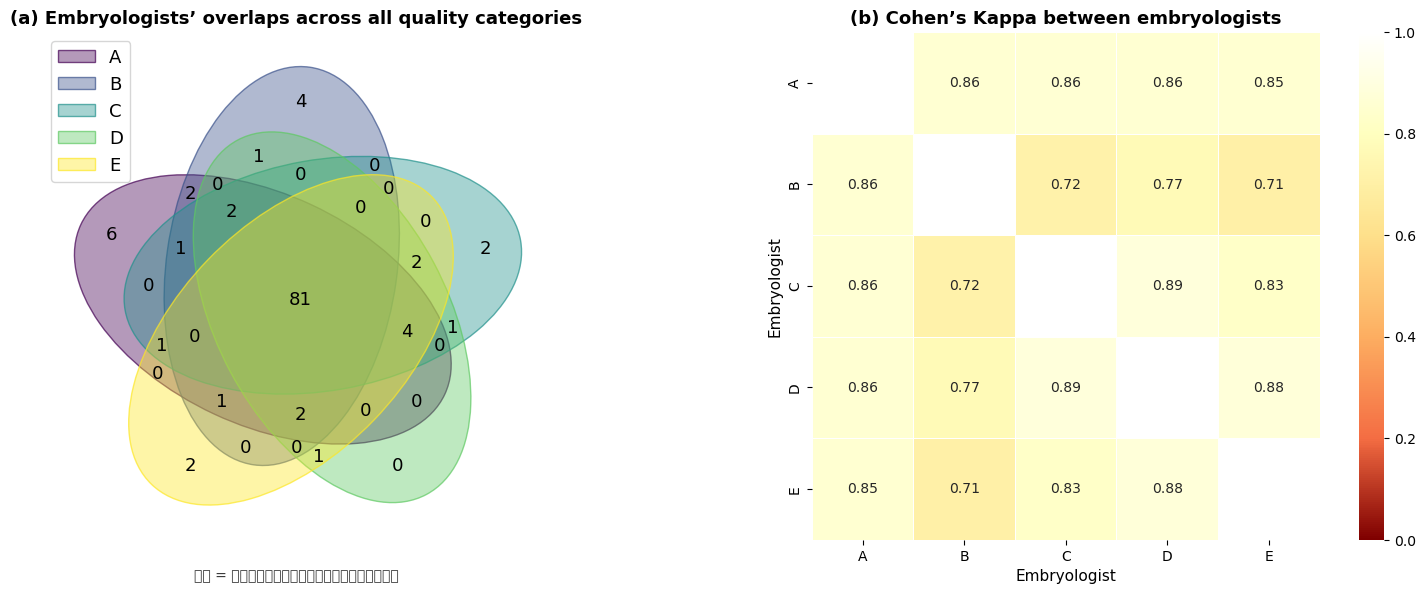

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from sklearn.metrics import cohen_kappa_score
from matplotlib.colors import LinearSegmentedColormap
from venn import venn  

# =========================
# 1️⃣ 读取并映射质量
# =========================
df = pd.read_csv("../../Assessment_comparison.csv", sep=r"\t|,|;", engine="python", encoding="utf-8-sig")
df.rename(columns={df.columns[0]: "EmbryoID"}, inplace=True)

def map_quality(grade):
    if not isinstance(grade, str):
        return np.nan
    grade = grade.strip().upper()
    if "MORULA" in grade:
        return "Morula"
    if len(grade) < 3:
        return np.nan
    expansion, icm, te = grade[0], grade[1], grade[2]
    g3 = grade[:3]
    if g3 in {"3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"}:
        return "Fair"
    if expansion >= "3" and (
        (icm == "A" and te == "A")
        or (icm == "A" and te == "B")
        or (icm == "B" and te == "A")
    ):
        return "Good"
    return "Poor"

experts = ["A", "B", "C", "D", "E"]
for col in experts:
    df[f"{col}_q"] = df[col].apply(map_quality)

# =========================
# 2️⃣ 五专家 Venn 图数据
# =========================
expert_sets = {
    exp: {
        f"{embryo}|{label}"
        for embryo, label in zip(df["EmbryoID"], df[f"{exp}_q"])
        if pd.notna(label)
    }
    for exp in experts
}

# =========================
# 3️⃣ 计算 Cohen’s Kappa 矩阵
# =========================
kappa_matrix = pd.DataFrame(np.eye(len(experts)), index=experts, columns=experts)
for a, b in combinations(experts, 2):
    subset = df[[f"{a}_q", f"{b}_q"]].dropna()
    kappa = np.nan if subset.empty else cohen_kappa_score(subset.iloc[:, 0], subset.iloc[:, 1])
    kappa_matrix.loc[a, b] = kappa
    kappa_matrix.loc[b, a] = kappa

# =========================
# 4️⃣ 自定义颜色映射（高一致性 = 白色）
# =========================
white_hot = LinearSegmentedColormap.from_list(
    "white_hot", ["#7f0000", "#f46d43", "#fdae61", "#fee08b", "#ffffbf", "#ffffff"]
)

# =========================
# 5️⃣ 绘制并排图像 (Supplementary Figure 1)
# =========================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- (a) Venn 图 ---
venn(expert_sets, fmt="{size}", legend_loc="upper left", ax=axes[0])
axes[0].set_title("(a) Embryologists’ overlaps across all quality categories", fontsize=13, fontweight="bold")
axes[0].annotate(
    "计数 = 在这些专家中得到完全相同质量等级的胚胎数",
    xy=(0.5, -0.08), xycoords="axes fraction",
    ha="center", fontsize=10, color="#333333"
)

# --- (b) Cohen’s Kappa 热图 ---
mask = np.eye(len(kappa_matrix), dtype=bool)  # ✅ 只遮住对角线
sns.heatmap(
    kappa_matrix.astype(float),
    annot=True,
    mask=mask,               # 只隐藏对角线上的注释
    cmap=white_hot,
    vmin=0, vmax=1,
    linewidths=0.7, linecolor="white",
    cbar=True,
    square=True,
    ax=axes[1],
    fmt=".2f"
)
axes[1].set_title("(b) Cohen’s Kappa between embryologists", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Embryologist", fontsize=11)
axes[1].set_ylabel("Embryologist", fontsize=11)

plt.tight_layout()
plt.show()